# Drug recommender: learned models, holdout, and clinical validation

This notebook picks up where `01_targets_baselines` stopped. The bar there was **B1 genomic rules: precision@5 ≈ 0.25** in
cross-validation, with no personalized signal at all for the third of patients who carry no actionable lesion.

| Section | Question |
|---|---|
| 1 | Do learned models beat the genomic rules? (5-fold CV inside Waves1+2) |
| 2 | Does tumor maturation state add to mutations? (ablation) |
| 3 | Who benefits? (subgroups) |
| 4 | Which drugs are predictable? |
| 5 | Does it hold on new patients? (Waves3+4, scored once) |
| 6 | Does predicted drug sensitivity relate to clinical outcome? |
| 7 | Verdict |

**Models.** **M1** = one ridge regression per drug, predicting that drug's z-score from patient features. **M2** = one
gradient-boosted model over all (patient, drug) pairs, with drug descriptors (drug id, kinase family, "drug targets one of this
patient's mutated genes"). Both are fit only on the training fold. Results are regenerated by
`python -m src.run_models [--holdout]` and `python -m src.clinical`. This notebook reads their saved tables.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from src.rank_eval import summarise
T = Path("results/tables")
INK, MUTED, BLUE, ORANGE, GREEN = "#0b0b0b", "#8a8984", "#2a78d6", "#eb6834", "#2e9e6a"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
                     "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 200)
cv = pd.read_csv(T / "models_cv_per_patient.csv", index_col=[0, 1])
ho = pd.read_csv(T / "models_holdout_per_patient.csv", index_col=[0, 1])
ORDER = ["Random", "B0 population", "B1 genomic rules", "M1 ridge: mutations", "M1 ridge: +cell types",
         "M1 ridge: expression only", "M1 ridge: all", "M2 xgb: mutations", "M2 xgb: all",
         "B1 -> M1 all", "B1 -> M2 all", "M1 shuffled labels"]
def col(n):
    return ORANGE if n.startswith("B1 genomic") else BLUE if n.startswith("M1") and "shuffled" not in n else GREEN if n.startswith(("M2", "B1 ->")) else MUTED
def summary(pp):
    rows = {}
    for n in ORDER:
        s = summarise(pp.xs(n, level="model"))
        rows[n] = s["mean"].to_dict() | {f"{m}_lo": s.loc[m, "ci_lo"] for m in s.index} | {f"{m}_hi": s.loc[m, "ci_hi"] for m in s.index}
    return pd.DataFrame(rows).T
S_cv, S_ho = summary(cv), summary(ho)
S_cv[["prec@5", "lift@5", "ndcg@10", "spearman", "regret"]].round(3)

,prec@5,lift@5,ndcg@10,spearman,regret
Random,0.179,-0.002,0.225,0.001,2.184
B0 population,0.188,0.007,0.245,0.003,2.344
B1 genomic rules,0.252,0.072,0.295,0.024,2.014
M1 ridge: mutations,0.289,0.108,0.335,0.153,1.798
M1 ridge: +cell types,0.320,0.139,0.382,0.240,1.672
M1 ridge: expression only,0.293,0.113,0.364,0.244,1.806
M1 ridge: all,0.328,0.148,0.393,0.248,1.633
M2 xgb: mutations,0.295,0.114,0.334,0.134,1.909
M2 xgb: all,0.299,0.119,0.366,0.192,1.768
B1 -> M1 all,0.321,0.141,0.382,0.244,1.642


---
## 1. Learned models vs the rules (cross-validation within Waves1+2)

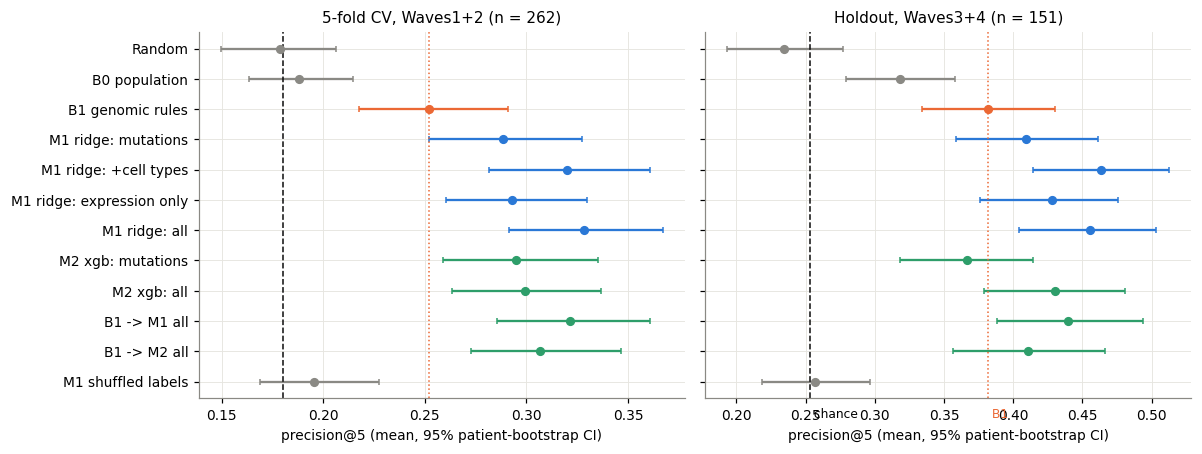

,Δprec@5 vs B1,lo,hi
model,,,
Random,-0.073,-0.105,-0.042
B0 population,-0.064,-0.091,-0.038
B1 genomic rules,0.000,0.000,0.000
M1 ridge: mutations,0.037,0.010,0.063
M1 ridge: +cell types,0.068,0.039,0.098
M1 ridge: all,0.076,0.050,0.104
M1 ridge: expression only,0.041,0.011,0.071
M2 xgb: mutations,0.043,0.018,0.067
M2 xgb: all,0.047,0.021,0.075


In [2]:
def forest(S, title, ax):
    y = np.arange(len(ORDER))[::-1]
    for yi, n in zip(y, ORDER):
        ax.errorbar(S.loc[n, "prec@5"], yi, xerr=[[S.loc[n, "prec@5"] - S.loc[n, "prec@5_lo"]], [S.loc[n, "prec@5_hi"] - S.loc[n, "prec@5"]]],
                    fmt="o", color=col(n), ms=5, capsize=2)
    ax.axvline(S["prevalence"].iloc[0], color=INK, ls="--", lw=1)
    ax.axvline(S.loc["B1 genomic rules", "prec@5"], color=ORANGE, ls=":", lw=1)
    ax.set_yticks(y, ORDER); ax.set_xlabel("precision@5 (mean, 95% patient-bootstrap CI)"); ax.set_title(title)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
forest(S_cv, "5-fold CV, Waves1+2 (n = 262)", axes[0]); forest(S_ho, "Holdout, Waves3+4 (n = 151)", axes[1])
axes[1].text(S_ho["prevalence"].iloc[0], -1.2, " chance", fontsize=8); axes[1].text(S_ho.loc["B1 genomic rules", "prec@5"], -1.2, " B1", color=ORANGE, fontsize=8)
plt.tight_layout(); plt.show()
pd.read_csv(T / "models_cv_paired_vs_B1.csv", index_col=0)

**Reading it.** The dashed line is chance (each patient's prevalence of truly sensitive drugs), the dotted orange line is B1.

* **M1 ridge with all features is the best model:** precision@5 **0.33** vs **0.25** for B1 and 0.18 for chance. Because every model
  is graded on the same patients, the cleanest comparison is the *paired* difference: **+0.076 [0.050, 0.104]** over B1. About 1.6 of
  its 5 recommendations are truly sensitive drugs, vs 1.3 for B1 and 0.9 by chance.
* It also improves the whole-list ranking (Spearman 0.25 vs 0.02), which B1 by design cannot.
* **The shuffled-label control is at chance** (0.195, lift CI includes 0), so the gain is not an artefact of the pipeline.
* **M2 (xgboost) is worse than M1** (0.30). With ~270 training patients, sharing across drugs did not pay off against simple
  per-drug ridge. Putting the rules on top of M1 (`B1 -> M1`) doesn't help either: M1 already learns the FLT3 signal.

---
## 2. Does maturation state add to mutations?

This is the paper's central claim turned into a predictive test: same model (M1), different feature blocks.

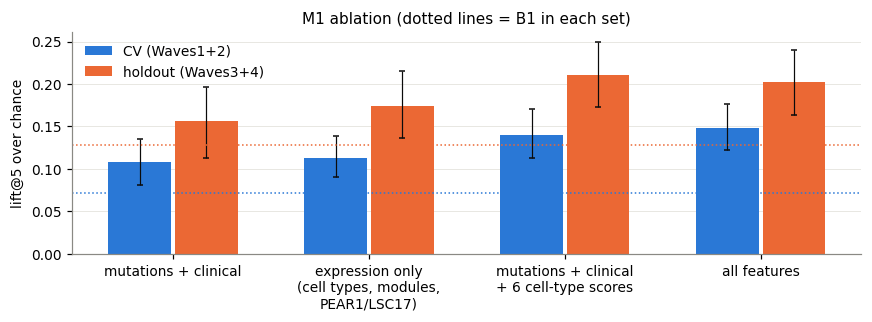

In [3]:
abl = ["M1 ridge: mutations", "M1 ridge: expression only", "M1 ridge: +cell types", "M1 ridge: all"]
lbl = ["mutations + clinical", "expression only\n(cell types, modules,\nPEAR1/LSC17)", "mutations + clinical\n+ 6 cell-type scores", "all features"]
fig, ax = plt.subplots(figsize=(8, 3))
for i, n in enumerate(abl):
    for k, (S, off, c) in enumerate([(S_cv, -0.17, BLUE), (S_ho, 0.17, ORANGE)]):
        ax.bar(i + off, S.loc[n, "lift@5"], 0.32, color=c, label=["CV (Waves1+2)", "holdout (Waves3+4)"][k] if i == 0 else None)
        ax.errorbar(i + off, S.loc[n, "lift@5"], yerr=[[S.loc[n, "lift@5"] - S.loc[n, "lift@5_lo"]], [S.loc[n, "lift@5_hi"] - S.loc[n, "lift@5"]]], color=INK, capsize=2, lw=0.8)
ax.axhline(S_cv.loc["B1 genomic rules", "lift@5"], color=BLUE, ls=":", lw=1); ax.axhline(S_ho.loc["B1 genomic rules", "lift@5"], color=ORANGE, ls=":", lw=1)
ax.set_xticks(range(4), lbl); ax.set_ylabel("lift@5 over chance"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_title("M1 ablation (dotted lines = B1 in each set)"); plt.tight_layout(); plt.show()

**Reading it.** Mutations alone already beat the rules a little (the model learns weights instead of hand-written rules). **Adding
the six cell-type scores is the biggest single step** (CV lift 0.108 → 0.139; holdout 0.156 → 0.210). Modules and PEAR1/LSC17 add
little on top. Expression alone is about as good as mutations alone, and the two are complementary. This is the predictive
version of Bottomly et al.'s finding: **maturation state carries drug-response information that genomics does not.**

---
## 3. Who benefits?

In [4]:
sub = {}
for tag, path in [("CV", "models_cv_subgroups.csv"), ("holdout", "models_holdout_subgroups.csv")]:
    s = pd.read_csv(T / path, header=[0, 1], index_col=[0, 1])["prec@5"]
    s = s[["Random", "B1 genomic rules", "M1 ridge: mutations", "M1 ridge: all"]]
    s.insert(0, "n", s.index.get_level_values("n"))
    sub[tag] = s.droplevel("n")
pd.concat(sub, axis=1).round(3)

CV                                                           holdout                                                          
model                  n Random B1 genomic rules M1 ridge: mutations M1 ridge: all       n Random B1 genomic rules M1 ridge: mutations M1 ridge: all
subgroup                                                                                                                                            
FLT3-ITD              60  0.283            0.497               0.497         0.557      38  0.289            0.426               0.442         0.516
RAS pathway           62  0.129            0.265               0.294         0.332      41  0.161            0.444               0.527         0.522
no actionable lesion  94  0.153            0.123               0.211         0.245      50  0.260            0.300               0.328         0.416

**Reading it.** (Random is the chance column for each group.)
* **No actionable lesion**, the group where B1 equals B0 and gives no personalization: M1 doubles precision in CV (**0.25 vs 0.12**,
  chance 0.15) and gains 0.12 on the holdout (**0.42 vs 0.30**). **This is the project's main result:** the model gives a useful
  ranking to patients that genotype-matched rules leave without one. (This group also includes the few patients without DNA-seq.)
* **FLT3-ITD:** M1 matches or slightly beats the rules (0.56 vs 0.50 CV). It doesn't lose the known biology.
* **RAS pathway:** M1 improves on the MEK-inhibitor rule in CV (0.33 vs 0.27), and on the holdout (0.52 vs 0.44).

---
## 4. Which drugs are predictable?

Per-drug Spearman between predicted and observed z, across held-out patients.

In [5]:
pdc = pd.read_csv(T / "models_cv_per_drug.csv", index_col=0); pdh = pd.read_csv(T / "models_holdout_per_drug.csv", index_col=0)
key = ["Venetoclax", "Cytarabine", "Azacytidine", "Sorafenib", "Quizartinib (AC220)", "Gilteritinib", "Midostaurin", "Crenolanib",
       "Trametinib (GSK1120212)", "Selumetinib (AZD6244)"]
tab = pd.DataFrame({"CV: mutations": pdc["M1 ridge: mutations"], "CV: all": pdc["M1 ridge: all"],
                    "holdout: mutations": pdh["M1 ridge: mutations"], "holdout: all": pdh["M1 ridge: all"]})
print("median over all drugs:"); print(tab.median().round(3).to_string())
tab.loc[key].round(2)

median over all drugs:
CV: mutations         0.203
CV: all               0.308
holdout: mutations    0.205
holdout: all          0.301


,CV: mutations,CV: all,holdout: mutations,holdout: all
drug,,,,
Venetoclax,0.20,0.65,0.43,0.77
Cytarabine,0.35,0.45,0.21,0.31
Azacytidine,0.05,0.13,0.04,0.20
Sorafenib,0.49,0.57,0.46,0.52
Quizartinib (AC220),0.47,0.48,0.26,0.30
Gilteritinib,0.12,0.21,0.15,0.23
Midostaurin,0.50,0.50,0.37,0.44
Crenolanib,0.47,0.59,0.53,0.59
Trametinib (GSK1120212),0.33,0.57,0.30,0.58


**Reading it.**
* **Venetoclax is the standout:** Spearman 0.20 → **0.65** in CV and 0.43 → **0.77** on the holdout once expression is added. This is the
  paper's progenitor-vs-monocytic biology, and it's directly clinically relevant (venetoclax + azacitidine is standard for unfit
  patients).
* **MEK inhibitors** (trametinib, selumetinib) also jump with expression (monocytic tumors respond), from ~0.2–0.3 to ~0.55–0.65.
* **FLT3 inhibitors** are predictable from mutations alone (0.4–0.5), and expression adds a little.
* **Cytarabine is moderate** (0.45 CV, 0.31 holdout). **Azacytidine is barely predictable** (0.13–0.20).

---
## 5. Holdout on Waves3+4 (scored once, after the model list was frozen)

The right-hand panel in section 1 is the holdout. Ranking and conclusions match CV:

In [6]:
pd.read_csv(T / "models_holdout_paired_vs_B1.csv", index_col=0)

,Δprec@5 vs B1,lo,hi
model,,,
Random,-0.147,-0.195,-0.099
B0 population,-0.064,-0.102,-0.026
B1 genomic rules,0.000,0.000,0.000
M1 ridge: mutations,0.028,-0.007,0.062
M1 ridge: +cell types,0.082,0.044,0.121
M1 ridge: all,0.074,0.034,0.117
M1 ridge: expression only,0.046,0.003,0.091
M2 xgb: mutations,-0.015,-0.048,0.019
M2 xgb: all,0.049,0.015,0.083


* **M1 all: precision@5 0.456 vs B1 0.381, paired gain +0.074 [0.034, 0.117].** The CV gain (+0.076) replicated almost exactly on
  patients accrued later.
* All absolute numbers are higher than in CV because **Waves3+4 samples are more drug-sensitive overall**: 25% of their tested pairs
  fall below the cutoff, vs 18% in Waves1+2 (z is scaled with Waves1+2 statistics). This shift also gives B0 some lift on the
  holdout (0.06). Compare models against each other and against chance *within* the same set, not across sets. A likely cause is
  assay or processing drift between waves, worth one sentence in the limitations.
* M2 xgboost with mutations only fails to beat B1 on the holdout. M1 is the model to present.

---
## 6. Clinical validation: cytarabine sensitivity vs induction outcome

**Cohort:** modeling patients sampled at initial diagnosis who received standard-chemotherapy induction with a known response
(CR/CRi vs refractory): **n = 239, 74 refractory**. A stricter subset with a 7+3 / HiDAC regimen recorded: n = 175, 45 refractory.
**Predicted** cytarabine z is out-of-sample for every patient (out-of-fold CV predictions for Waves1+2, holdout predictions for
Waves3+4). **Observed** z exists only for patients whose cells were actually tested with cytarabine (n = 145).

In [7]:
print(pd.read_csv(T / "clinical_univariate.csv").round(3).to_string(index=False)); print()
print(pd.read_csv(T / "clinical_auroc.csv").round(3).to_string(index=False)); print()
pd.read_csv(T / "clinical_logistic.csv").query("term in ['obs_z', 'pred_z']").round(3)

                  cohort  score   n  AUROC (higher z -> refractory)  Mann-Whitney p
standard-chemo induction  obs_z 145                           0.488           0.827
standard-chemo induction pred_z 239                           0.486           0.739
   7+3 / HiDAC confirmed  obs_z 110                           0.559           0.342
   7+3 / HiDAC confirmed pred_z 175                           0.444           0.265

                  cohort                                   model   n  events (refractory)  cv AUROC    sd  LR test p vs ELN+age
standard-chemo induction                               ELN + age 238                   74     0.739 0.007                   NaN
standard-chemo induction       ELN + age + observed cytarabine z 145                   40     0.707 0.015                 0.936
standard-chemo induction      ELN + age + predicted cytarabine z 238                   74     0.736 0.007                 0.125
standard-chemo induction               ELN + age + PEAR1 + LSC17 23

,cohort,model,term,n,OR per SD,OR lo,OR hi,p
0,standard-chemo induction,ELN + age + observed cytarabine z,obs_z,145,1.017,0.671,1.541,0.936
1,standard-chemo induction,ELN + age + predicted cytarabine z,pred_z,238,0.783,0.572,1.073,0.128
4,standard-chemo induction,ELN + age + predicted z + PEAR1 + LSC17,pred_z,238,0.795,0.573,1.101,0.167
7,7+3 / HiDAC confirmed,ELN + age + observed cytarabine z,obs_z,110,1.170,0.712,1.923,0.535
8,7+3 / HiDAC confirmed,ELN + age + predicted cytarabine z,pred_z,175,0.683,0.463,1.008,0.055
11,7+3 / HiDAC confirmed,ELN + age + predicted z + PEAR1 + LSC17,pred_z,175,0.694,0.459,1.050,0.084


**Reading it.**
* **The observed ex vivo cytarabine result does not predict induction response** (univariate AUROC 0.49; adjusted OR 1.02 per SD,
  p = 0.94). This is a finding about the *assay*, not our model: in this cohort, cytarabine killing in a dish does not track
  whether 7+3 induces remission. Plausible reasons: the patient receives an anthracycline too (not on the panel); a 3-day culture
  misses the marrow microenvironment and pharmacokinetics; and induction failure is partly driven by patient fitness.
* **Predicted cytarabine z adds nothing to ELN + age** in the full cohort (CV AUROC 0.736 vs 0.739). In the 7+3 subset it's borderline
  (p ≈ 0.05), but **in the wrong direction** (predicted resistance ↔ *fewer* refractory). We treat that as noise, not a finding.
* PEAR1/LSC17 don't add to ELN + age here either (the paper's PEAR1 result was for survival).

In [8]:
pd.read_csv(T / "clinical_cox.csv").round(3)

,model,n,deaths,term,HR per SD,lo,hi,p,C-index
0,pred_z alone,229,100,pred_z,1.500,1.216,1.849,0.000,0.611
1,pred_z + ELN + age,229,100,pred_z,1.330,1.090,1.623,0.005,0.754
2,obs_z + ELN + age,142,60,obs_z,0.911,0.721,1.150,0.432,0.740


**Survival is the one positive clinical signal.** A higher *predicted* cytarabine resistance score is associated with shorter overall
survival, **HR 1.33 per SD [1.09, 1.62], p = 0.005, after adjusting for ELN2017 and age** (n = 229, 100 deaths). The *observed* score
shows nothing (HR 0.91, p = 0.43). So the predicted score most likely works as a **molecular risk score** (it summarizes the
maturation and mutation profile), not as a proxy for the lab test. It's worth reporting as an exploratory, retrospective association.
It shouldn't be framed as "the recommender predicts who responds to chemo". It has not yet been checked in an external cohort (TCGA-LAML).

---
## 6b. External check: does the survival signal replicate in TCGA-LAML?

**Pre-specified test:** apply the *frozen* M1 model (fit on Beat AML Waves1+2 only, same as for the holdout) to TCGA-LAML and run the
same Cox model, OS ~ predicted cytarabine z + ELN + age. Data are public (cBioPortal; `scripts/get_tcga.sh`), code in `src/tcga.py`.

How features cross platforms: cell-type and module scores use TCGA genes z-scored within TCGA and projected onto the PC1 loadings
learned on Beat AML; all expression features are then rescaled to the Beat AML training distribution. Mutations come from TCGA exome
calls, fusions from karyotype. ELN2017 is approximated from karyotype + mutations (no FLT3-ITD allelic ratio). APL is excluded in the
primary analysis (different treatment).

In [9]:
pd.read_csv(T / "tcga_cox.csv").round(3)

,cohort,model,n,deaths,C-index,HR per SD,lo,hi,p
0,non-APL (primary),pred_z alone,138,91,0.508,1.040,0.827,1.308,0.739
1,non-APL (primary),pred_z + ELN + age,138,91,0.640,0.937,0.739,1.186,0.587
2,non-APL (primary),ELN + age (reference),138,91,0.638,NaN,NaN,NaN,NaN
3,all incl. APL,pred_z alone,151,94,0.508,0.965,0.771,1.209,0.759
4,all incl. APL,pred_z + ELN + age,151,94,0.663,0.879,0.699,1.106,0.273
5,all incl. APL,ELN + age (reference),151,94,0.658,NaN,NaN,NaN,NaN


**Reading it. The survival signal does not replicate.** In TCGA (138 non-APL patients, 91 deaths), HR = **0.94 [0.74, 1.19]** after
ELN + age, vs 1.33 [1.09, 1.62] in Beat AML. The predicted score adds nothing to ELN + age (C-index 0.640 vs 0.638).

Checks that the null is not a broken pipeline:
* The mapped Monocyte-like score separates FAB M4/M5 (monocytic) cases strongly (mean 3.6 vs −1.6), so the expression features transfer.
* Predicted scores have a similar spread in both cohorts (SD 0.31 vs 0.40), and ELN + age behaves as expected (C-index 0.64).
* A first run had a bug (genes with missing TCGA values made 7 expression features NaN). It was fixed **before** interpreting the
  result, and the fixed run is the one shown. The conclusion didn't change.
* It's not explained by TCGA being all de novo: in Beat AML the HR is unchanged after adjusting for de novo status (1.32), and similar in
  de novo patients only (1.28, p = 0.05).

Possible reasons, which can't be separated here: the Beat AML association was a chance finding (one test among several in section 6);
TCGA's exome calls under-detect two of the model's strongest inputs (FLT3-ITD 16% vs 24% in Beat AML, SRSF2 2% vs 12%); and the
cohorts differ in era (2001–2010) and treatment.

---
## 7. Verdict

**The recommender arm is a solid, presentable result:**
1. A simple per-drug ridge model on interpretable features beats genotype-matched rules by ~8 points of precision@5, in CV
   **and** on a temporally held-out cohort scored once (+0.074 [0.034, 0.117]).
2. The gain comes largely from **maturation state** (cell-type scores) and is concentrated where rules can't help: patients
   **without an actionable mutation**.
3. **Venetoclax** response is well predicted from expression (ρ = 0.77 on the holdout), reproducing the paper's biology as a predictive result.
4. Controls behave: shuffled labels at chance, the population baseline at chance in CV, and leakage tests pass.

**The clinical arm is mostly null and should be framed honestly:** ex vivo cytarabine response (measured or predicted) does not
predict induction response here, so we can't claim the recommender predicts clinical chemo response. The predicted score was associated
with overall survival in Beat AML (HR 1.33), but this **did not replicate in TCGA-LAML** (HR 0.94), so it shouldn't be presented as a
finding, only as a non-replicated exploratory association.

**Suggested framing:** *"Molecular profiles, especially tumor maturation state, can stand in for the ex vivo drug screen for drug
prioritization, including for patients without actionable mutations. Whether ex vivo sensitivity translates to clinical response
remains open: for cytarabine it did not in this cohort."* With the remaining time, the strongest
extension is a venetoclax-focused deep-dive (explanations of single patients' recommendations), since that's where the recommender is strongest.